# P3 · Notebook 01 — Model Optimization Lab (SANA-Sprint)

**Goal:** make text-to-image **fast, small and still good**, and prove it with numbers.

**What this notebook does (just press `Runtime → Run all`):**
1. Loads the **baseline**: the SANA-Sprint *teacher*. This is the exact slow model (0.6B, 20 steps + guidance) that SANA-Sprint was distilled from, so the comparison is fair.
2. Loads **SANA-Sprint** (same size, 1–4 steps) and adds optimizations **one at a time**. That ladder *is* your ablation study.
3. For every setup it measures the P3 metrics: **CLIP score, FID/KID, latency, peak GPU memory, model size**.
4. Saves to Google Drive: a results table, charts, a grid of hard prompts, and a draft **`eval_P3_<TeamID>.md`**.

**Before running:** `Runtime → Change runtime type → T4 GPU` (free). T4 is fine for this lab, and it's also the cheapest GPU you can host the app on later, so these numbers will match your live server. L4/A100 are just faster.

**Time:** QUICK mode ≈ 1–2 hours on T4 (≈ 1 hour on L4). FULL mode takes several hours (run it once at the end for the final numbers).
If Colab disconnects, just **Run all** again: finished setups are skipped automatically.

## The setups we test (the "ablation ladder")

| Name | What changes | P3 optimization type |
|---|---|---|
| `B0_teacher_20step` | **Baseline**: teacher, 20 steps + classifier-free guidance (≈40 network passes per image) | none |
| `S1_sprint_2step` | Distilled SANA-Sprint, 2 steps, no guidance pass (2 network passes per image) | Reduced sampling steps (distillation) |
| `S2_sprint_1step` | Same, 1 step | Reduced sampling steps |
| `S3_sprint_4step` | Same, 4 steps | Check: do more steps help quality? |
| `S4_te8bit` | S1 + text encoder (Gemma-2, ~2.6B) in 8-bit | Quantization |
| `S5_te4bit` | S1 + text encoder in 4-bit (NF4) | Quantization |
| `S6_te4bit_tr8bit` | S5 + image transformer in 8-bit | Quantization |
| `S7_compile` | S1 + `torch.compile` | Inference-pipeline optimization |
| `S8_res768`, `S9_res512` | S1 at a smaller output size | Resolution optimization |
| `S10_noCHI` | S1 without the long hidden instruction SANA adds to every prompt | Prompt-encoding optimization |
| `F1_fallback_lowmem` | 1 step, 512px, 4-bit text encoder, 8-bit transformer | Fallback for constrained devices |
| `M1_lowmem_1024` | 4-bit reader with its word table on the CPU + 8-bit drawer + tiled decoding, 1024px | Memory optimization (quantization + offloading) |
| `M2_lowmem_768` | M1 at 768px | Memory + resolution optimization |
| `M3_lowmem_1024_tr4bit` | M1 with a 4-bit drawer (the smallest setup) | Memory optimization |
| `M5_reader_streamed` | Reader kept in RAM and streamed to the GPU block by block + 4-bit drawer + tiled decoding | Memory optimization (group offloading) |
| `Q1_bestof2_768`, `Q2_bestof2_M3` | Make 2 pictures, keep the one a separate CLIP (ViT-B/16) prefers | Quality: best-of-N selection |
| `F2_fallback_offload` *(optional)* | S1 with CPU offload. Needs more than ~13 GB of system RAM, so it **crashes free Colab** | Fallback for tiny GPUs |
| `X1_tr_int8ao_compile` *(optional)* | S1 + torchao int8 transformer + compile | Quantization + compile |
| `X2_sprint_1.6B` *(optional)* | Bigger 1.6B Sprint, 2 steps | Architecture size comparison |

**Latent-space optimization is built in:** SANA's DC-AE autoencoder squeezes a 1024×1024 image into a 32×32 latent grid (32× per side, compared with 8× in Stable Diffusion). That's a big reason it's fast.

## 1 · Settings (edit these)

In [1]:
# ============================ SETTINGS ============================
QUICK = False                       # True: fast exploring run (~1 h on L4). False: final numbers (~3 h).
N_EVAL = 100 if QUICK else 500     # COCO val captions used as prompts for CLIP / FID / KID
N_REAL = 1000 if QUICK else 5000   # real COCO val images used as the FID/KID reference
N_SPEED_RUNS = 5 if QUICK else 10  # timed single-image runs per setup (after warm-up)
INCLUDE_OPTIONAL = False           # also test torchao-int8 + compile and the bigger 1.6B model
RUN_ONLY = ["B0_teacher_20step", "S1_sprint_2step", "S8_res768", "M2_lowmem_768", "M3_lowmem_1024_tr4bit"]                    # e.g. ["B0_teacher_20step", "S1_sprint_2step"] to run only these
FORCE_RERUN = False                # True = redo setups even if results already exist
SAVE_TO_DRIVE = True               # keep results in Google Drive (survives disconnects)
SEED = 0
TEAM_ID = "T00"                    # your team ID -> eval_P3_<TEAM_ID>.md
USNS = "1RUA24CSE0335,1RUA24CSE0340,1RUA24CSE0347,1RUA25CSE0553"            # first line of the eval file: all USNs, comma separated
BASELINE = "B0_teacher_20step"
CLIP_TOLERANCE = 1.0               # "recommended" = fastest setup whose CLIP is within this of the baseline

## 2 · Install libraries (~1–2 min)

In [2]:
import subprocess, sys

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *pkgs], check=True)

pip_install("diffusers", "transformers", "accelerate", "bitsandbytes", "torchmetrics[image]",
            "torch-fidelity", "sentencepiece", "protobuf", "tabulate")
if INCLUDE_OPTIONAL:
    pip_install("torchao")
print("Libraries installed.")

Libraries installed.


## 3 · Check the GPU

In [3]:
import os, gc, json, time, math, random, zipfile, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
import diffusers, transformers
from diffusers import SanaPipeline, SanaSprintPipeline, PipelineQuantizationConfig
from diffusers import BitsAndBytesConfig as DiffusersBnbConfig
from transformers import BitsAndBytesConfig as TransformersBnbConfig

warnings.filterwarnings("ignore", category=FutureWarning)
assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > GPU (L4 recommended), then Run all again."

DEV = "cuda"
GPU_NAME = torch.cuda.get_device_name(0)
CAP = torch.cuda.get_device_capability(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
DTYPE = torch.bfloat16 if CAP[0] >= 8 else torch.float16   # T4 (capability 7.5) has no bfloat16
EVAL_BS = 4 if VRAM_GB >= 20 else 2                         # images per batch when generating the eval set
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

print(f"GPU: {GPU_NAME} | {VRAM_GB:.1f} GB | compute capability {CAP} | dtype: {DTYPE}")
print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
if CAP[0] < 8:
    print("Note: this GPU has no bfloat16 (e.g. T4), so everything runs in float16. That's fine. "
          "The smoke test in section 8 checks that images don't come out black.")

GPU: Tesla T4 | 15.6 GB | compute capability (7, 5) | dtype: torch.float16
torch 2.14.1+cu130 | diffusers 0.42.1 | transformers 5.22.2
Note: this GPU has no bfloat16 (e.g. T4), so everything runs in float16. That's fine. The smoke test in section 8 checks that images don't come out black.


## 4 · Where results are saved

In [4]:
OUT = Path("/content/P3_out")
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT = Path("/content/drive/MyDrive/P3_T2I/01_optimization_lab")
    except Exception as e:
        print("Could not mount Google Drive, saving inside this Colab session only:", e)

MODE_TAG = f"{'quick' if QUICK else 'full'}_n{N_EVAL}"
RES_DIR = OUT / f"results_{MODE_TAG}"      # one JSON per setup (this is what makes resume work)
FIG_DIR = OUT / f"figures_{MODE_TAG}"
HARD_DIR = OUT / "hard_prompts"             # images for the hard-prompt grid / failure analysis
WORK = Path("/content/p3_work")             # big temporary files (COCO, generated eval images)
GEN_DIR = WORK / f"gen_{MODE_TAG}"
for d in [OUT, RES_DIR, FIG_DIR, HARD_DIR, WORK, GEN_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print("Results folder:", OUT)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/P3_T2I/01_optimization_lab


## 5 · Data: MS-COCO 2017 captions + images

**Train/validation split:** evaluation prompts come **only from COCO *val* 2017**. COCO *train* captions are saved separately for notebook 02 (training the adaptive router). They are never used for evaluation.

Downloads ≈ 1 GB the first time (captions file + the 5,000 validation images).

In [5]:
COCO = WORK / "coco"
COCO.mkdir(exist_ok=True)
ANN_ZIP = COCO / "annotations_trainval2017.zip"
IMG_ZIP = COCO / "val2017.zip"

def download(url, dest):
    if dest.exists():
        return
    tmp = dest.with_suffix(".part")
    print("Downloading", url)
    subprocess.run(["wget", "-q", "-O", str(tmp), url], check=True)
    tmp.rename(dest)

download("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ANN_ZIP)
download("http://images.cocodataset.org/zips/val2017.zip", IMG_ZIP)

def first_caption_per_image(caps):
    out = {}
    for a in caps["annotations"]:
        out.setdefault(a["image_id"], " ".join(a["caption"].split()))
    return out

with zipfile.ZipFile(ANN_ZIP) as z:
    caps_val = json.loads(z.read("annotations/captions_val2017.json"))
    caps_train = json.loads(z.read("annotations/captions_train2017.json"))

val_caption = first_caption_per_image(caps_val)
id2file = {im["id"]: im["file_name"] for im in caps_val["images"]}
val_ids = sorted(val_caption)
random.Random(SEED).shuffle(val_ids)
EVAL_IDS = val_ids[:N_EVAL]
EVAL_PROMPTS = [val_caption[i] for i in EVAL_IDS]
REAL_IDS = val_ids[:N_REAL]

train_caption = first_caption_per_image(caps_train)
train_ids = sorted(train_caption)
random.Random(SEED).shuffle(train_ids)
TRAIN_ITEMS = [{"id": i, "caption": train_caption[i]} for i in train_ids[:5000]]
del caps_train, train_caption

json.dump({"split": "COCO-2017 val", "seed": SEED, "ids": EVAL_IDS, "prompts": EVAL_PROMPTS},
          open(OUT / f"eval_prompts_{MODE_TAG}.json", "w"), indent=1)
json.dump({"split": "COCO-2017 train (notebook 02 only, never used for evaluation)", "items": TRAIN_ITEMS},
          open(OUT / "train_prompts.json", "w"))
print(f"{len(EVAL_PROMPTS)} eval prompts (val) | {len(TRAIN_ITEMS)} train prompts saved for later")
print("Example prompt:", EVAL_PROMPTS[0])

# Real reference images for FID/KID: centre square crop, 512x512
REAL_DIR = WORK / f"real512_{N_REAL}"
REAL_DIR.mkdir(exist_ok=True)

def center_square(img, size=512):
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((size, size), Image.BICUBIC)

missing = [i for i in REAL_IDS if not (REAL_DIR / f"{i}.jpg").exists()]
if missing:
    with zipfile.ZipFile(IMG_ZIP) as z:
        for iid in tqdm(missing, desc="Preparing real COCO images"):
            with z.open(f"val2017/{id2file[iid]}") as f:
                center_square(Image.open(f).convert("RGB")).save(REAL_DIR / f"{iid}.jpg", quality=95)
print(f"{len(REAL_IDS)} real reference images ready.")

500 eval prompts (val) | 5000 train prompts saved for later
Example prompt: A young lad swings his Wilson tennis racquet.


Preparing real COCO images:   0%|          | 0/5000 [00:00<?, ?it/s]

5000 real reference images ready.


In [6]:
# Hand-written hard prompts: several objects, colours/attributes and positions (P3 advanced requirement #1).
# The last few are known weak spots (left/right, counting, text): good material for the failure-case analysis.
HARD_PROMPTS = [
    "a red cube on top of a blue sphere, next to a sleeping orange cat, studio lighting",
    "two cats on a blue sofa, the black cat on the left and the white cat on the right",
    "a teddy bear wearing sunglasses reading a newspaper on a park bench",
    "a green vintage car parked under a streetlight on a rainy night, reflections on the wet road",
    "a glass of orange juice and a croissant on a white plate, a laptop in the background, morning light",
    "an astronaut riding a horse on a red desert planet, two moons in the sky",
    "a bowl of ramen with a soft-boiled egg, chopsticks resting on the bowl, top-down view",
    "a lighthouse on a cliff during a storm, huge waves, dramatic clouds",
    "a small yellow bird sitting on a big purple flower, blurry green background",
    "a dog to the left of a bicycle and a red umbrella to the right of the bicycle",
    "exactly five apples in a woven basket on a kitchen table",
    "a wooden sign that says OPEN hanging on a shop door",
]
SPEED_PROMPTS = EVAL_PROMPTS[:3] + HARD_PROMPTS[:2]   # fixed prompts for the latency test

## 6 · Setups

In [7]:
REPOS = {
    "teacher": "Efficient-Large-Model/Sana_Sprint_0.6B_1024px_teacher_diffusers",
    "sprint": "Efficient-Large-Model/Sana_Sprint_0.6B_1024px_diffusers",
    "sprint_1.6B": "Efficient-Large-Model/Sana_Sprint_1.6B_1024px_diffusers",
}

CONFIGS = [
    dict(name="B0_teacher_20step", model="teacher", steps=20, note="Baseline: teacher, 20 steps + CFG"),
    dict(name="S1_sprint_2step", model="sprint", steps=2, note="Distilled Sprint, 2 steps"),
    dict(name="S2_sprint_1step", model="sprint", steps=1, note="Sprint, 1 step"),
    dict(name="S3_sprint_4step", model="sprint", steps=4, note="Sprint, 4 steps"),
    dict(name="S4_te8bit", model="sprint", steps=2, te_quant="8bit", note="S1 + 8-bit text encoder"),
    dict(name="S5_te4bit", model="sprint", steps=2, te_quant="4bit", note="S1 + 4-bit text encoder"),
    dict(name="S6_te4bit_tr8bit", model="sprint", steps=2, te_quant="4bit", tr_quant="8bit",
         note="S5 + 8-bit transformer"),
    dict(name="S7_compile", model="sprint", steps=2, compile=True, note="S1 + torch.compile"),
    dict(name="S8_res768", model="sprint", steps=2, res=768, note="S1 at 768px"),
    dict(name="S9_res512", model="sprint", steps=2, res=512, note="S1 at 512px"),
    dict(name="S10_noCHI", model="sprint", steps=2, no_chi=True, note="S1 without hidden prompt instruction"),
    dict(name="F1_fallback_lowmem", model="sprint", steps=1, res=512, te_quant="4bit", tr_quant="8bit",
         note="Fallback: lowest memory, still on GPU"),
    # Memory-saving setups: the reader's word table (256k words, 1.18 GB) lives on the CPU + tiled decoding
    dict(name="M1_lowmem_1024", model="sprint", steps=2, res=1024, te_quant="4bit", tr_quant="8bit",
         te_embed_cpu=True, vae_tiling=True, note="4-bit reader (word table on CPU) + 8-bit drawer + tiled decode, 1024px"),
    dict(name="M2_lowmem_768", model="sprint", steps=2, res=768, te_quant="4bit", tr_quant="8bit",
         te_embed_cpu=True, vae_tiling=True, note="M1 at 768px (speed + memory sweet spot)"),
    dict(name="M3_lowmem_1024_tr4bit", model="sprint", steps=2, res=1024, te_quant="4bit", tr_quant="4bit",
         te_embed_cpu=True, vae_tiling=True, note="M1 with a 4-bit drawer (smallest possible)"),
    # NEW: push memory further: the reader lives in system RAM and is streamed to the GPU block by block
    dict(name="M5_reader_streamed", model="sprint", steps=2, res=1024, tr_quant="4bit", vae_tiling=True,
         reader_offload=True, note="Reader in RAM, streamed to GPU per block + 4-bit drawer + tiled decode"),
    # NEW: push quality: make 2 pictures, keep the one a SEPARATE CLIP (ViT-B/16) likes best
    dict(name="Q1_bestof2_768", model="sprint", steps=2, res=768, best_of=2,
         note="S8 + best-of-2 (picked by CLIP ViT-B/16, scored by CLIP ViT-L/14)"),
    dict(name="Q2_bestof2_M3", model="sprint", steps=2, res=1024, te_quant="4bit", tr_quant="4bit",
         te_embed_cpu=True, vae_tiling=True, best_of=2, note="M3 + best-of-2"),
]
if INCLUDE_OPTIONAL:
    CONFIGS += [
        dict(name="F2_fallback_offload", model="sprint", steps=2, offload=True,
             note="Fallback: CPU offload (needs >13 GB system RAM: crashes free Colab)"),
        dict(name="X1_tr_int8ao_compile", model="sprint", steps=2, tr_quant="int8_torchao", compile=True,
             note="S1 + torchao int8 transformer + compile"),
        dict(name="X2_sprint_1.6B", model="sprint_1.6B", steps=2, note="Bigger 1.6B Sprint, 2 steps"),
    ]
if RUN_ONLY:
    CONFIGS = [c for c in CONFIGS if c["name"] in RUN_ONLY]
for c in CONFIGS:
    c.setdefault("res", 1024)
print(f"{len(CONFIGS)} setups:", ", ".join(c["name"] for c in CONFIGS))

5 setups: B0_teacher_20step, S1_sprint_2step, S8_res768, M2_lowmem_768, M3_lowmem_1024_tr4bit


## 7 · Helper functions (loading, timing, memory, scoring)

In [8]:
def free_gpu():
    """Free GPU memory AND give freed RAM back to the system (free Colab has only ~12.7 GB RAM)."""
    gc.collect()
    torch.cuda.empty_cache()
    try:
        import ctypes
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

def sync_time():
    torch.cuda.synchronize()
    return time.perf_counter()

def build_quant_config(cfg):
    """Which parts of the pipeline get quantized, and how."""
    qm = {}
    te, tr = cfg.get("te_quant"), cfg.get("tr_quant")
    if te == "8bit":
        qm["text_encoder"] = TransformersBnbConfig(load_in_8bit=True)
    elif te == "4bit":
        qm["text_encoder"] = TransformersBnbConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                   bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
    if tr == "8bit":
        qm["transformer"] = DiffusersBnbConfig(load_in_8bit=True)
    elif tr == "4bit":
        qm["transformer"] = DiffusersBnbConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                               bnb_4bit_compute_dtype=DTYPE)
    elif tr == "int8_torchao":
        from diffusers import TorchAoConfig
        from torchao.quantization import Int8WeightOnlyConfig
        qm["transformer"] = TorchAoConfig(Int8WeightOnlyConfig())
    return PipelineQuantizationConfig(quant_mapping=qm) if qm else None

def load_pipe(cfg):
    cls = SanaPipeline if cfg["model"] == "teacher" else SanaSprintPipeline
    kwargs = {"torch_dtype": DTYPE}
    qc = build_quant_config(cfg)
    if qc is not None:
        kwargs["quantization_config"] = qc
    if cfg.get("offload"):
        pipe = cls.from_pretrained(REPOS[cfg["model"]], **kwargs)
        pipe.enable_model_cpu_offload()
    else:
        try:
            # Load weights straight onto the GPU so they don't pile up in RAM first.
            pipe = cls.from_pretrained(REPOS[cfg["model"]], device_map="cuda", **kwargs)
        except Exception as e:
            print("device_map='cuda' not supported here, loading the normal way:", str(e)[:120])
            free_gpu()
            pipe = cls.from_pretrained(REPOS[cfg["model"]], **kwargs)
            pipe.to(DEV)
    if cfg.get("te_embed_cpu"):
        move_word_table_to_cpu(pipe)
    if cfg.get("vae_tiling"):
        pipe.vae.enable_tiling()        # decode in tiles: removes the memory spike at the end
    if cfg.get("reader_offload"):
        from diffusers.hooks import apply_group_offloading
        apply_group_offloading(pipe.text_encoder, onload_device=torch.device(DEV), offload_device=torch.device("cpu"),
                               offload_type="block_level", num_blocks_per_group=2)
        free_gpu()
        print("  reader moved to RAM, streamed to the GPU 2 blocks at a time")
    if cfg.get("compile"):
        pipe.transformer.compile()
    pipe.set_progress_bar_config(disable=True)
    return pipe

class CPUEmbedding(torch.nn.Module):
    """The reader's word table, kept on the CPU (saves ~1.2 GB of GPU memory).
    Keeps Gemma's built-in x48 scale (sqrt(hidden_size)): newer transformers apply it INSIDE the table,
    and dropping it breaks the prompt understanding (CLIP fell from 27 to 9 in our first attempt)."""
    def __init__(self, emb):
        super().__init__()
        self.weight_cpu = emb.weight.detach().to("cpu")
        self.num_embeddings, self.embedding_dim = self.weight_cpu.shape
        scale = getattr(emb, "embed_scale", None)
        self.scale = float(scale) if scale is not None else 1.0
    def forward(self, input_ids):
        out = torch.nn.functional.embedding(input_ids.to("cpu"), self.weight_cpu)
        return (out * self.scale).to(input_ids.device)

def move_word_table_to_cpu(pipe):
    te = pipe.text_encoder
    old = te.embed_tokens
    test_ids = torch.tensor([[2, 651, 4401, 235265]], device=old.weight.device)
    ref = old(test_ids).float().cpu()
    te.embed_tokens = CPUEmbedding(old)
    diff = (ref - te.embed_tokens(test_ids).float().cpu()).abs().max().item()
    print(f"  word table moved to CPU (scale x{te.embed_tokens.scale:.1f}), max difference vs original: {diff:.6f}")
    assert diff < 1e-3, "CPU word table doesn't match the original: stop, the pictures would be wrong"
    del old
    free_gpu()

def call_kwargs(cfg):
    res = cfg["res"]
    kw = {"height": res, "width": res, "num_inference_steps": cfg["steps"]}
    if cfg["model"] == "teacher":
        kw["guidance_scale"] = 4.5
    else:
        # Sprint's default intermediate timestep only works for exactly 2 steps; it must be None otherwise.
        kw["intermediate_timesteps"] = 1.3 if cfg["steps"] == 2 else None
        if cfg.get("no_chi"):
            kw["complex_human_instruction"] = None
    if res != 1024:
        # Without this the pipeline secretly renders ~1024px and shrinks it, so you'd save no time.
        kw["use_resolution_binning"] = False
    return kw

@torch.inference_mode()
def generate(pipe, cfg, prompts, seeds):
    k = cfg.get("best_of", 1)
    all_prompts = [p for p in prompts for _ in range(k)]
    gens = [torch.Generator("cpu").manual_seed(int(s) + 50000 * j) for s in seeds for j in range(k)]   # same noise for every setup
    images = pipe(prompt=all_prompts, generator=gens, **call_kwargs(cfg)).images
    return pick_best(pipe, list(prompts), images, k) if k > 1 else images

def pick_best(pipe, prompts, images, k):
    """Best-of-k: a SEPARATE CLIP (ViT-B/16) picks; the reported CLIP score uses ViT-L/14, so we don't grade our own pick."""
    if getattr(pipe, "_selector", None) is None:
        from transformers import CLIPModel, CLIPProcessor
        pipe._selector = (CLIPModel.from_pretrained("openai/clip-vit-base-patch16", torch_dtype=torch.float16).to(DEV).eval(),
                          CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16"))
    model, proc = pipe._selector
    inp = proc(text=[p for p in prompts for _ in range(k)], images=images, return_tensors="pt",
               padding=True, truncation=True, max_length=77).to(DEV)
    inp["pixel_values"] = inp["pixel_values"].half()
    out = model(**inp)
    sim = (out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
           * out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)).sum(-1).view(-1, k)
    return [images[i * k + int(b)] for i, b in enumerate(sim.argmax(1).tolist())]

In [9]:
def measure_speed(pipe, cfg, base_alloc):
    """Latency of ONE image (what a user waits for) + peak GPU memory while generating."""
    for i in range(3 if cfg.get("compile") else 2):          # warm-up (compile needs an extra one)
        generate(pipe, cfg, [SPEED_PROMPTS[i % len(SPEED_PROMPTS)]], [SEED])
    torch.cuda.reset_peak_memory_stats()
    times = []
    for i in range(N_SPEED_RUNS):
        t0 = sync_time()
        generate(pipe, cfg, [SPEED_PROMPTS[i % len(SPEED_PROMPTS)]], [SEED + i])
        times.append(sync_time() - t0)
    return {
        "latency_mean_s": float(np.mean(times)),
        "latency_p50_s": float(np.median(times)),
        "latency_p90_s": float(np.percentile(times, 90)),
        "peak_vram_gb": (torch.cuda.max_memory_allocated() - base_alloc) / 1e9,
    }

def stage_breakdown(pipe, cfg):
    """Where does the time go? Text encoder vs image transformer vs decoder."""
    acc = {"text_encoder": 0.0, "transformer": 0.0, "vae_decode": 0.0}
    def wrap(fn, key):
        def timed(*a, **k):
            t0 = sync_time()
            out = fn(*a, **k)
            acc[key] += sync_time() - t0
            return out
        return timed
    te, tr, vae = pipe.text_encoder, pipe.transformer, pipe.vae
    orig = (te.forward, tr.forward, vae.decode)
    te.forward, tr.forward, vae.decode = (wrap(orig[0], "text_encoder"), wrap(orig[1], "transformer"),
                                          wrap(orig[2], "vae_decode"))
    try:
        t0 = sync_time()
        generate(pipe, cfg, [SPEED_PROMPTS[0]], [SEED])
        total = sync_time() - t0
    finally:
        te.forward, tr.forward, vae.decode = orig
    acc["other"] = max(total - sum(acc.values()), 0.0)
    return {f"ms_{k}": v * 1000 for k, v in acc.items()}

PARAMS_FILE = OUT / "param_counts.json"
PARAMS = json.load(open(PARAMS_FILE)) if PARAMS_FILE.exists() else {}

def module_bytes(m):
    try:
        return m.get_memory_footprint()
    except Exception:
        return sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers()))

def component_sizes(pipe, cfg):
    """Model size per part (MB of weights) and parameter counts (millions)."""
    out = {}
    quantized = {"text_encoder": cfg.get("te_quant"), "transformer": cfg.get("tr_quant"), "vae": None}
    for comp in ["text_encoder", "transformer", "vae"]:
        m = getattr(pipe, comp)
        out[f"size_{comp}_mb"] = module_bytes(m) / 1e6
        key = f"{cfg['model']}/{comp}"
        if not quantized[comp] and key not in PARAMS:
            PARAMS[key] = sum(p.numel() for p in m.parameters())
        out[f"params_{comp}_M"] = PARAMS[key] / 1e6 if key in PARAMS else float("nan")
    out["size_total_mb"] = sum(out[f"size_{c}_mb"] for c in ["text_encoder", "transformer", "vae"])
    out["params_total_M"] = sum(out[f"params_{c}_M"] for c in ["text_encoder", "transformer", "vae"])
    json.dump(PARAMS, open(PARAMS_FILE, "w"), indent=1)
    return out

In [10]:
_SCORERS = {}

@torch.no_grad()
def clip_score_dir(img_dir, ids, prompts, bs=32):
    """CLIP similarity (ViT-L/14) between each image and its prompt, x100. Higher = better prompt match."""
    from transformers import CLIPModel, CLIPProcessor
    # Loaded fresh each time and deleted after, so it never sits in RAM while the next model loads.
    model = CLIPModel.from_pretrained("openai/clip-vit-large-patch14", device_map="cuda").eval()
    proc = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")
    scores = []
    for i in range(0, len(ids), bs):
        imgs = [Image.open(img_dir / f"{j}.jpg").convert("RGB") for j in ids[i:i + bs]]
        inp = proc(text=list(prompts[i:i + bs]), images=imgs, return_tensors="pt",
                   padding=True, truncation=True, max_length=77).to(DEV)
        out = model(**inp)
        img_e = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
        txt_e = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
        scores += (100 * (img_e * txt_e).sum(-1)).clamp(min=0).cpu().tolist()
    del model, proc, out, inp
    free_gpu()
    return float(np.mean(scores))

def _load_batch(files, size=299):
    arr = np.stack([np.asarray(Image.open(f).convert("RGB").resize((size, size), Image.BICUBIC)) for f in files])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(255).to(DEV)

@torch.no_grad()
def fid_kid_dir(img_dir, ids, bs=64):
    """FID and KID vs real COCO photos (Inception features). Lower = more realistic.
    KID is more trustworthy than FID when you only have a few hundred images."""
    from torchmetrics.image.fid import FrechetInceptionDistance
    from torchmetrics.image.kid import KernelInceptionDistance
    if "fid" not in _SCORERS:
        fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(DEV)
        kid = KernelInceptionDistance(feature=2048, subset_size=min(100, N_EVAL), normalize=True,
                                      reset_real_features=False).to(DEV)
        real = [REAL_DIR / f"{i}.jpg" for i in REAL_IDS]
        for i in tqdm(range(0, len(real), bs), desc="Real-image features (only once)"):
            x = _load_batch(real[i:i + bs])
            fid.update(x, real=True)
            kid.update(x, real=True)
        _SCORERS["fid"] = (fid, kid)
    fid, kid = _SCORERS["fid"]
    fid.to(DEV)
    kid.to(DEV)
    fid.reset()
    kid.reset()
    files = [img_dir / f"{j}.jpg" for j in ids]
    for i in range(0, len(files), bs):
        x = _load_batch(files[i:i + bs])
        fid.update(x, real=False)
        kid.update(x, real=False)
    f = float(fid.compute())
    k_mean, k_std = kid.compute()
    fid.to("cpu")
    kid.to("cpu")
    free_gpu()
    return f, float(k_mean), float(k_std)

In [11]:
SHOW_KEYS = ["latency_mean_s", "peak_vram_gb", "size_total_mb", "clip_score", "fid", "n_black_images", "status"]

def run_config(cfg):
    name = cfg["name"]
    res_file = RES_DIR / f"{name}.json"
    if res_file.exists() and not FORCE_RERUN:
        old = json.load(open(res_file))
        if old.get("status") == "ok":
            print(f"[skip] {name}: already done")
            return old
    print(f"\n=== {name}: {cfg.get('note', '')}")
    row = {k: cfg.get(k) for k in ["name", "note", "model", "steps", "res", "te_quant", "tr_quant",
                                   "compile", "offload", "no_chi"]}
    pipe = None
    try:
        free_gpu()
        base_alloc = torch.cuda.memory_allocated()
        t0 = time.time()
        pipe = load_pipe(cfg)
        row["load_time_s"] = time.time() - t0
        row["weights_vram_gb"] = (torch.cuda.memory_allocated() - base_alloc) / 1e9
        row.update(component_sizes(pipe, cfg))
        row.update(measure_speed(pipe, cfg, base_alloc))
        if not cfg.get("compile") and not cfg.get("offload") and not cfg.get("reader_offload"):
            row.update(stage_breakdown(pipe, cfg))

        # Hard prompts -> images for the side-by-side grid and the failure analysis
        hdir = HARD_DIR / name
        hdir.mkdir(exist_ok=True)
        for k in range(0, len(HARD_PROMPTS), EVAL_BS):
            batch = HARD_PROMPTS[k:k + EVAL_BS]
            imgs = generate(pipe, cfg, batch, [SEED + k + j for j in range(len(batch))])
            for j, im in enumerate(imgs):
                im.resize((512, 512), Image.LANCZOS).save(hdir / f"{k + j:02d}.jpg", quality=95)

        # Eval set (COCO val captions) -> CLIP / FID / KID
        gdir = GEN_DIR / name
        gdir.mkdir(parents=True, exist_ok=True)
        n_black = 0
        for k in tqdm(range(0, N_EVAL, EVAL_BS), desc=f"{name}: eval images"):
            ids, prompts = EVAL_IDS[k:k + EVAL_BS], EVAL_PROMPTS[k:k + EVAL_BS]
            for iid, im in zip(ids, generate(pipe, cfg, prompts, [SEED + iid for iid in ids])):
                if np.asarray(im).max() < 10:
                    n_black += 1
                im.resize((512, 512), Image.LANCZOS).save(gdir / f"{iid}.jpg", quality=95)
        row["n_black_images"] = n_black

        pipe = None
        free_gpu()   # scorers run with the generator unloaded, so they don't affect memory numbers
        row["clip_score"] = clip_score_dir(gdir, EVAL_IDS, EVAL_PROMPTS)
        row["fid"], row["kid_mean"], row["kid_std"] = fid_kid_dir(gdir, EVAL_IDS)
        row["n_eval"] = N_EVAL
        row["status"] = "ok"
    except Exception as e:
        import traceback
        traceback.print_exc()
        row["status"] = f"failed: {type(e).__name__}: {str(e)[:300]}"
    finally:
        pipe = None
        free_gpu()
    row["gpu"], row["dtype"] = GPU_NAME, str(DTYPE)
    json.dump(row, open(res_file, "w"), indent=1)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items() if k in SHOW_KEYS})
    return row

## 8 · Smoke test: one image (~2–4 min the first time, mostly downloading)
If a picture shows up below, everything works.

model_index.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

SANA-Sprint 0.6B, 2 steps, 1024px: 1.16 s on Tesla T4


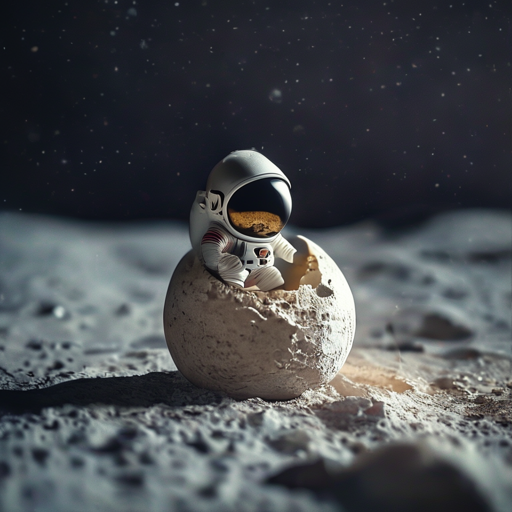

Image looks OK. Go ahead with section 9.


In [12]:
smoke = dict(name="smoke", model="sprint", steps=2, res=1024)
free_gpu()
pipe = load_pipe(smoke)
generate(pipe, smoke, ["warm-up"], [0])    # first call is always slow (GPU warm-up)
t0 = sync_time()
img = generate(pipe, smoke, ["a tiny astronaut hatching from an egg on the moon"], [0])[0]
print(f"SANA-Sprint 0.6B, 2 steps, 1024px: {sync_time() - t0:.2f} s on {GPU_NAME}")
pipe = None
free_gpu()
display(img.resize((512, 512)))
px = np.asarray(img)
if px.max() < 10 or px.std() < 2:
    print("PROBLEM: the image is black/blank. This is a float16 overflow. Stop here and report it (don't Run all).")
else:
    print("Image looks OK. Go ahead with section 9.")

## 9 · Run every setup (the long part)
Progress is saved after each setup. If Colab disconnects, **Run all** again and it continues where it stopped.

In [13]:
t_start = time.time()
for cfg in CONFIGS:
    run_config(cfg)
print(f"\nAll setups finished in {(time.time() - t_start) / 60:.1f} min")


=== B0_teacher_20step: Baseline: teacher, 20 steps + CFG


model_index.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

... (32 outputs left out)

  word table moved to CPU (scale x48.0), max difference vs original: 0.000000


M3_lowmem_1024_tr4bit: eval images:   0%|          | 0/250 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

{'size_total_mb': 2355.382, 'latency_mean_s': 1.567, 'peak_vram_gb': 2.859, 'n_black_images': 0, 'clip_score': 26.516, 'fid': 86.241, 'status': 'ok'}

All setups finished in 102.5 min


## 10 · Results table

In [14]:
rows = [json.load(open(RES_DIR / f"{c['name']}.json")) for c in CONFIGS if (RES_DIR / f"{c['name']}.json").exists()]
assert rows, "No results yet: run section 9 first."
df = pd.DataFrame(rows).set_index("name")
ok = df[df["status"] == "ok"].copy()
ok["kid_x1000"] = ok["kid_mean"] * 1000
if BASELINE in ok.index:
    b = ok.loc[BASELINE]
    ok["speedup_x"] = b["latency_mean_s"] / ok["latency_mean_s"]
    ok["mem_saving_x"] = b["peak_vram_gb"] / ok["peak_vram_gb"]
    ok["size_saving_x"] = b["size_total_mb"] / ok["size_total_mb"]
    ok["clip_vs_base"] = ok["clip_score"] - b["clip_score"]

COLS = [c for c in ["note", "steps", "res", "clip_score", "fid", "kid_x1000", "latency_mean_s", "latency_p90_s",
                    "peak_vram_gb", "size_total_mb", "speedup_x", "mem_saving_x", "clip_vs_base", "n_black_images"]
        if c in ok.columns]
display(ok[COLS].round(3))
failed = df[df["status"] != "ok"]
if len(failed):
    print("Setups that failed (the rest still count):\n" + failed["status"].to_string())
ok.to_csv(OUT / f"results_{MODE_TAG}.csv")

cands = ok[[not n.startswith("F") and n != BASELINE for n in ok.index]]   # fallbacks/baseline can't be "recommended"
if BASELINE in ok.index:
    cands = cands[cands["clip_score"] >= ok.loc[BASELINE, "clip_score"] - CLIP_TOLERANCE]
RECOMMENDED = cands["latency_mean_s"].idxmin() if len(cands) else None
print("\nRecommended setup to deploy (fastest with CLIP close to the baseline):", RECOMMENDED)

,note,steps,res,clip_score,fid,kid_x1000,latency_mean_s,latency_p90_s,peak_vram_gb,size_total_mb,speedup_x,mem_saving_x,clip_vs_base,n_black_images
name,,,,,,,,,,,,,,
B0_teacher_20step,"Baseline: teacher, 20 steps + CFG",20,1024,26.601,92.390,9.043,6.076,6.316,8.792,7036.939,1.000,1.000,0.000,0
S1_sprint_2step,"Distilled Sprint, 2 steps",2,1024,26.434,87.195,8.416,1.285,1.303,8.794,7040.188,4.729,1.000,-0.168,0
S8_res768,S1 at 768px,2,768,26.246,85.592,7.576,0.776,0.788,8.029,7040.188,7.829,1.095,-0.355,0
M2_lowmem_768,M1 at 768px (speed + memory sweet spot),2,768,26.269,85.524,6.472,1.210,1.283,2.994,2511.630,5.020,2.937,-0.333,0
M3_lowmem_1024_tr4bit,M1 with a 4-bit drawer (smallest possible),2,1024,26.516,86.241,6.878,1.567,1.601,2.859,2355.382,3.877,3.075,-0.085,0



Recommended setup to deploy (fastest with CLIP close to the baseline): S8_res768


## 11 · Charts (saved to the figures folder)

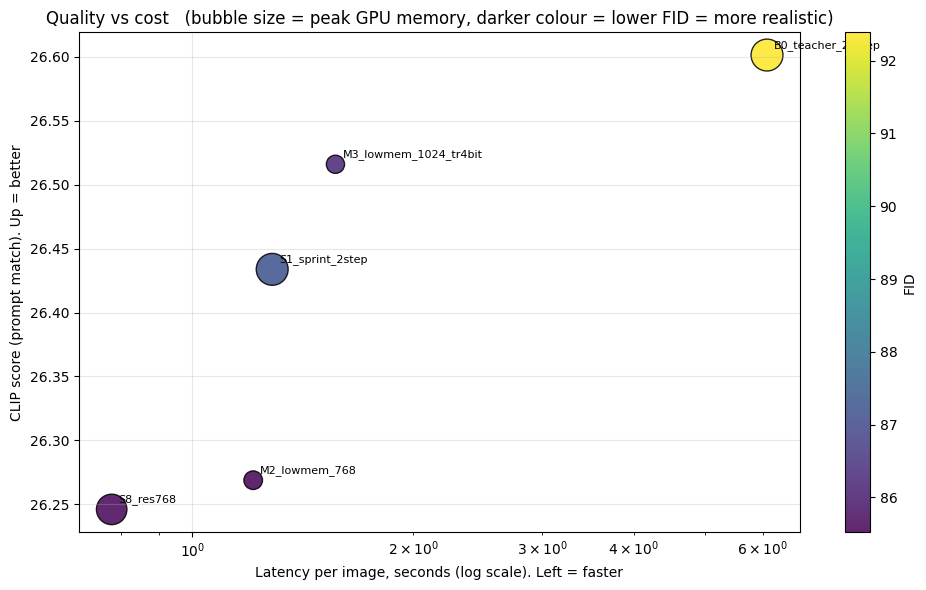

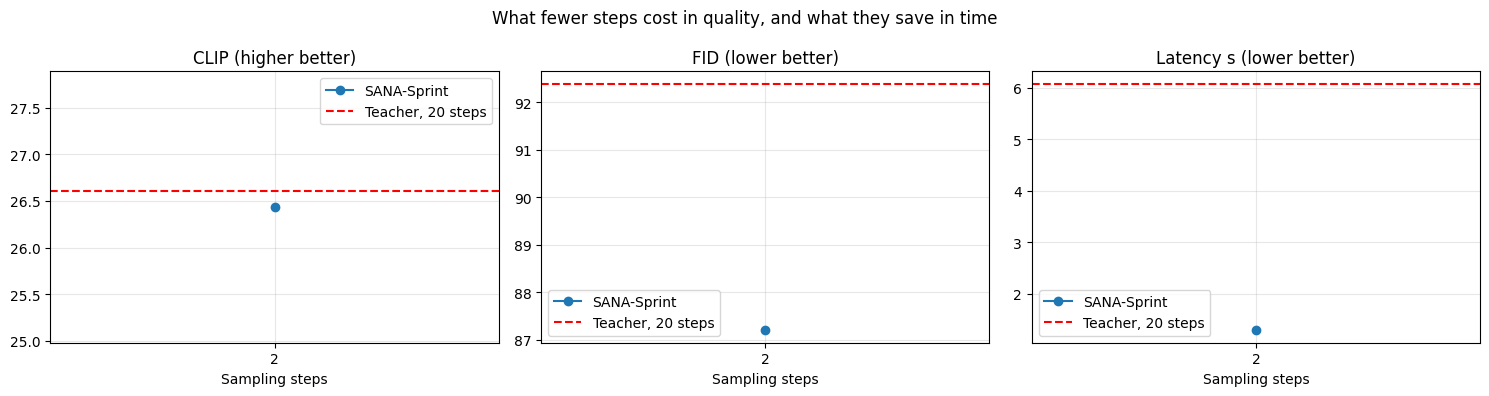

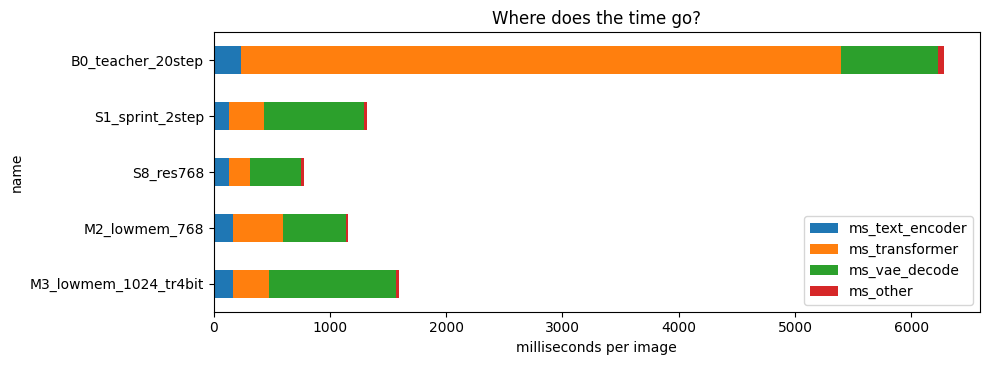

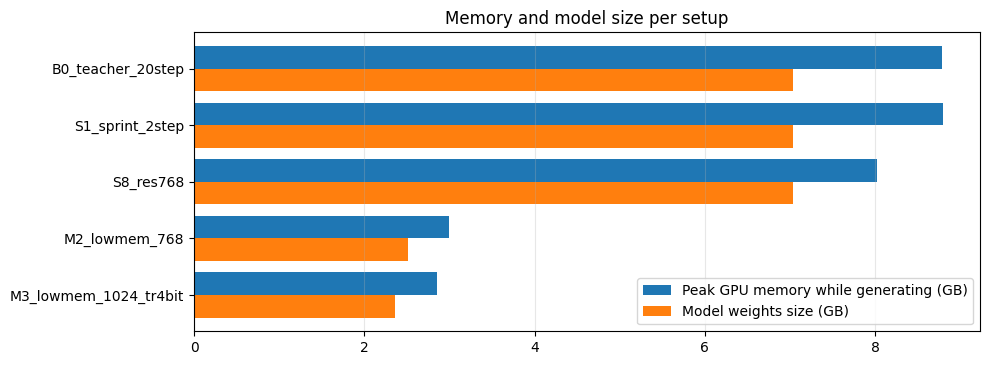

In [15]:
# 1) Quality vs cost: the single most important chart for the judges
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(ok["latency_mean_s"], ok["clip_score"], s=ok["peak_vram_gb"].clip(lower=0.2) * 60,
                c=ok["fid"], cmap="viridis", alpha=0.85, edgecolors="k")
for n, r in ok.iterrows():
    ax.annotate(n, (r["latency_mean_s"], r["clip_score"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Latency per image, seconds (log scale). Left = faster")
ax.set_ylabel("CLIP score (prompt match). Up = better")
ax.set_title("Quality vs cost   (bubble size = peak GPU memory, darker colour = lower FID = more realistic)")
plt.colorbar(sc, label="FID")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "quality_vs_cost.png", dpi=150)
plt.show()

# 2) Steps trade-off
steps_rows = [n for n in ["S2_sprint_1step", "S1_sprint_2step", "S3_sprint_4step"] if n in ok.index]
if steps_rows:
    s = ok.loc[steps_rows]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col, label in zip(axes, ["clip_score", "fid", "latency_mean_s"], ["CLIP (higher better)", "FID (lower better)", "Latency s (lower better)"]):
        ax.plot(s["steps"], s[col], "o-", label="SANA-Sprint")
        if BASELINE in ok.index:
            ax.axhline(ok.loc[BASELINE, col], color="r", ls="--", label="Teacher, 20 steps")
        ax.set_xlabel("Sampling steps")
        ax.set_xticks(list(s["steps"]))
        ax.set_title(label)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.suptitle("What fewer steps cost in quality, and what they save in time")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "steps_tradeoff.png", dpi=150)
    plt.show()

# 3) Where the time goes
ms_cols = [c for c in ["ms_text_encoder", "ms_transformer", "ms_vae_decode", "ms_other"] if c in ok.columns]
bd = ok[ms_cols].dropna() if ms_cols else pd.DataFrame()
if len(bd):
    bd.plot(kind="barh", stacked=True, figsize=(10, 0.45 * len(bd) + 1.5))
    plt.gca().invert_yaxis()
    plt.xlabel("milliseconds per image")
    plt.title("Where does the time go?")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "latency_breakdown.png", dpi=150)
    plt.show()

# 4) Memory and model size
fig, ax = plt.subplots(figsize=(10, 0.45 * len(ok) + 1.5))
y = np.arange(len(ok))
ax.barh(y - 0.2, ok["peak_vram_gb"], height=0.4, label="Peak GPU memory while generating (GB)")
ax.barh(y + 0.2, ok["size_total_mb"] / 1000, height=0.4, label="Model weights size (GB)")
ax.set_yticks(y)
ax.set_yticklabels(ok.index)
ax.invert_yaxis()
ax.legend()
ax.grid(alpha=0.3, axis="x")
plt.title("Memory and model size per setup")
plt.tight_layout()
plt.savefig(FIG_DIR / "memory.png", dpi=150)
plt.show()

## 12 · Hard prompts side by side
Use this grid to pick your **3 failure cases** (left/right, counting and text are the usual suspects).

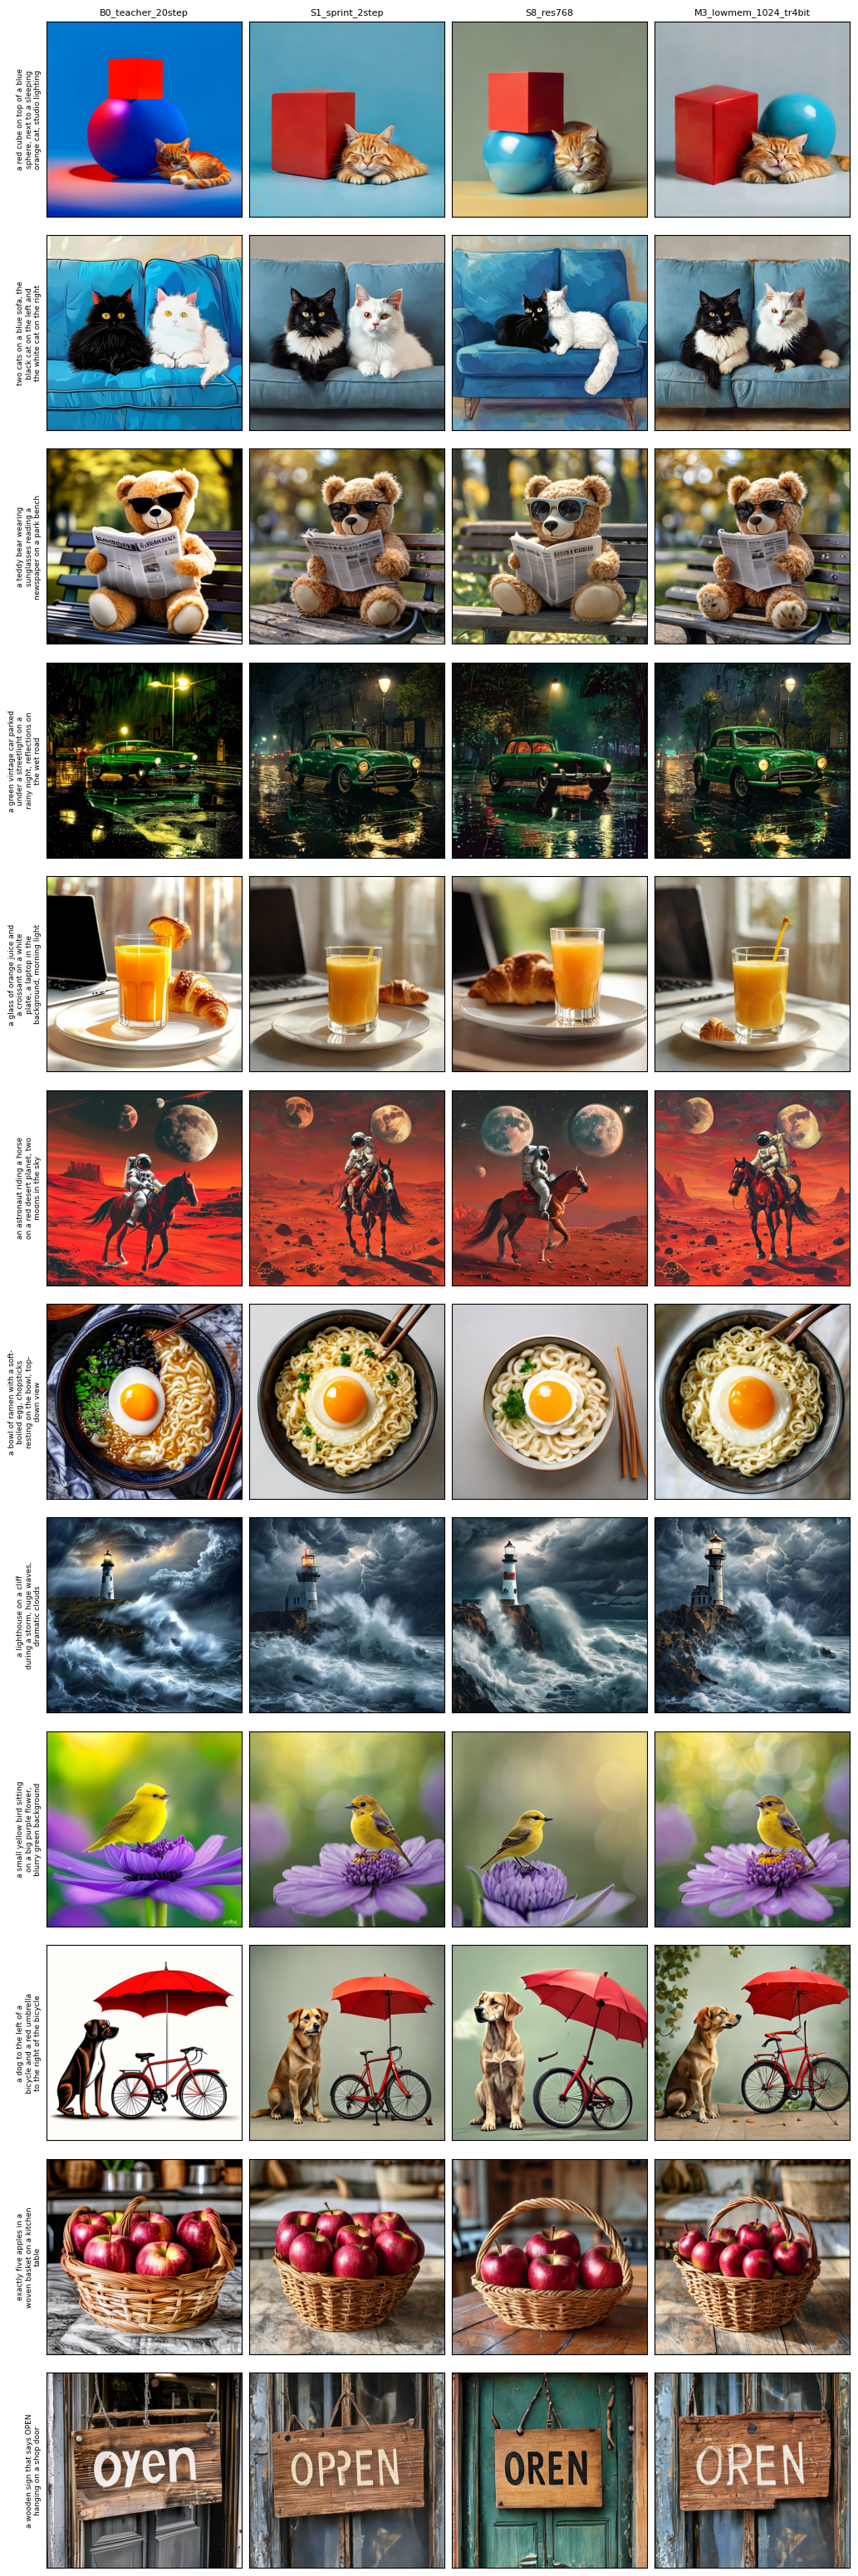

In [16]:
GRID_SETUPS = [n for n in [BASELINE, "S1_sprint_2step", "S8_res768", "M3_lowmem_1024_tr4bit", "S2_sprint_1step",
                           "S3_sprint_4step", "S9_res512"] if n in ok.index and (HARD_DIR / n).exists()]
n_rows, n_cols = len(HARD_PROMPTS), len(GRID_SETUPS)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.6 * n_rows))
axes = np.array(axes).reshape(n_rows, n_cols)
for r, prompt in enumerate(HARD_PROMPTS):
    for c, name in enumerate(GRID_SETUPS):
        ax = axes[r, c]
        f = HARD_DIR / name / f"{r:02d}.jpg"
        if f.exists():
            ax.imshow(Image.open(f))
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title(name, fontsize=8)
        if c == 0:
            ax.set_ylabel(textwrap.fill(prompt, 28), fontsize=6.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "hard_prompts_grid.jpg", dpi=110)
plt.show()

## 13 · Draft eval file (`eval_P3_<TeamID>.md`)
Metrics are in the order the hackathon brief asks for. In QUICK mode the file is marked DRAFT.

In [17]:
def fmt(v, nd=3):
    return "n/a" if v is None or (isinstance(v, float) and math.isnan(v)) else f"{v:.{nd}f}"

if BASELINE in ok.index and RECOMMENDED:
    b, o = ok.loc[BASELINE], ok.loc[RECOMMENDED]
    lines = [
        USNS,
        "",
        f"# Evaluation results: P3 (Resource-Efficient Text-to-Image), Team {TEAM_ID}",
        "",
    ]
    if QUICK:
        lines += ["> DRAFT from QUICK mode (small sample, so FID is noisy). Re-run with QUICK=False for final numbers.", ""]
    lines += [
        f"- **Baseline** `{BASELINE}`: SANA-Sprint teacher (0.6B), 20 steps + classifier-free guidance, 1024px",
        f"- **Optimized** `{RECOMMENDED}`: {o['note']}",
        f"- **Prompts:** {N_EVAL} captions from MS-COCO 2017 *val* (seed {SEED}). "
        f"FID/KID reference: {N_REAL} real COCO val images (512px centre crop)",
        f"- **Hardware:** {GPU_NAME}, {str(DTYPE).replace('torch.', '')}. Latency = mean of {N_SPEED_RUNS} "
        f"single-image runs after warm-up (GPU time only, no network)",
        "",
        "| # | Metric | Baseline | Optimized | Change |",
        "|---|---|---|---|---|",
        f"| 1 | CLIP similarity (ViT-L/14, x100), higher is better | {fmt(b.clip_score, 2)} | {fmt(o.clip_score, 2)} | {o.clip_score - b.clip_score:+.2f} |",
        f"| 2 | FID, lower is better (KID x1000 in brackets) | {fmt(b.fid, 2)} ({fmt(b.kid_x1000, 2)}) | {fmt(o.fid, 2)} ({fmt(o.kid_x1000, 2)}) | {o.fid - b.fid:+.2f} |",
        f"| 3 | Image generation latency (s) | {fmt(b.latency_mean_s)} | {fmt(o.latency_mean_s)} | {b.latency_mean_s / o.latency_mean_s:.1f}x faster |",
        f"| 4 | Peak GPU memory (GB) | {fmt(b.peak_vram_gb, 2)} | {fmt(o.peak_vram_gb, 2)} | {b.peak_vram_gb / o.peak_vram_gb:.2f}x less |",
        f"| 5 | Model size (MB, all weights) | {fmt(b.size_total_mb, 0)} | {fmt(o.size_total_mb, 0)} | {b.size_total_mb / o.size_total_mb:.2f}x smaller |",
        f"| 6 | Quality vs computational cost | 40 network passes per image | {int(o.steps)} passes per image | see table below and quality_vs_cost.png |",
        "",
        "## All setups (ablation study)",
        "",
        ok[COLS].round(3).to_markdown(),
        "",
    ]
    eval_name = f"eval_P3_{TEAM_ID}{'_DRAFT_quick' if QUICK else ''}.md"
    (OUT / eval_name).write_text("\n".join(lines))
    print(f"Saved {OUT / eval_name}\n")
    print("\n".join(lines))
else:
    print("Need both the baseline and at least one optimized setup to finish successfully first.")

Saved /content/drive/MyDrive/P3_T2I/01_optimization_lab/eval_P3_T00.md

1RUA24CSE0335,1RUA24CSE0340,1RUA24CSE0347,1RUA25CSE0553

# Evaluation results: P3 (Resource-Efficient Text-to-Image), Team T00

- **Baseline** `B0_teacher_20step`: SANA-Sprint teacher (0.6B), 20 steps + classifier-free guidance, 1024px
- **Optimized** `S8_res768`: S1 at 768px
- **Prompts:** 500 captions from MS-COCO 2017 *val* (seed 0). FID/KID reference: 5000 real COCO val images (512px centre crop)
- **Hardware:** Tesla T4, float16. Latency = mean of 10 single-image runs after warm-up (GPU time only, no network)

| # | Metric | Baseline | Optimized | Change |
|---|---|---|---|---|
| 1 | CLIP similarity (ViT-L/14, x100), higher is better | 26.60 | 26.25 | -0.36 |
| 2 | FID, lower is better (KID x1000 in brackets) | 92.39 (9.04) | 85.59 (7.58) | -6.80 |
| 3 | Image generation latency (s) | 6.076 | 0.776 | 7.8x faster |
| 4 | Peak GPU memory (GB) | 8.79 | 8.03 | 1.10x less |
| 5 | Model size (MB, all weights) | 7037

## 14 · How to read the results, and what comes next

**Reading the numbers**
- **`quality_vs_cost.png`:** the best setups sit **top-left** (fast *and* matching the prompt). This chart is the heart of your demo.
- **CLIP score:** higher means the picture matches the sentence better. Differences under ~0.5 are basically noise.
- **FID:** lower means more photo-realistic. With QUICK mode (100 images), FID is inflated and jumpy. Compare setups *with each other*, and lean on **KID** for small samples. Run FULL mode once for the final eval file.
- **`n_black_images` > 0:** numeric overflow (usually float16 on a T4). Switch to an L4/A100.
- **Latency here = GPU time only.** The real app adds network time, so keep a safety margin under the 10-second limit.

**Next notebooks**
- **02, adaptation + classical CV:** a small *router* trained on COCO **train** captions (saved as `train_prompts.json`) that picks 1/2/4 steps per prompt for a compute budget, checked on **val**. Plus colour correction, edge-aware filtering, a quality check and artifact detection.
- **03, deployment:** wrap the recommended setup in a web app and host it on Hugging Face, with Fast / Balanced / Quality modes and the fallback.